Check for pyTorch support for the GPU

In [1]:
import platform
import torch, torchvision

print("Python", platform.python_version(), "| PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("GPU:", p.name, f"| memory {p.total_memory / 1e9:.1f} GB")

Python 3.13.7 | PyTorch 2.14.1+cu126 | torchvision 0.29.1+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU | memory 6.4 GB


Get which classes belong to which crop

In [2]:
import json
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

SPLITS_DIR = Path("splits_v2")
classes = sorted(json.loads((SPLITS_DIR / "classes.json").read_text()), key=lambda c: c["index"])
CLASS_IDS = [c["id"] for c in classes]
CROPS = sorted({c["crop"] for c in classes})

crop_mask = torch.zeros(len(CROPS), len(CLASS_IDS), dtype=torch.bool)
for c in classes:
    crop_mask[CROPS.index(c["crop"]), c["index"]] = True

for i, crop in enumerate(CROPS):
    print(f"{crop:12s} {int(crop_mask[i].sum())} classes:", [CLASS_IDS[j] for j in crop_mask[i].nonzero().flatten()])

apple        3 classes: ['apple_scab', 'apple_cedar_rust', 'apple_healthy']
bell_pepper  2 classes: ['pepper_bacterial_spot', 'pepper_healthy']
corn         3 classes: ['corn_gray_leaf_spot', 'corn_northern_leaf_blight', 'corn_common_rust']
grape        2 classes: ['grape_black_rot', 'grape_healthy']
potato       2 classes: ['potato_early_blight', 'potato_late_blight']
tomato       8 classes: ['tomato_bacterial_spot', 'tomato_early_blight', 'tomato_late_blight', 'tomato_leaf_mold', 'tomato_septoria_leaf_spot', 'tomato_mosaic_virus', 'tomato_yellow_leaf_curl', 'tomato_healthy']


In [3]:
BACKBONES = {
    18: (models.resnet18, models.ResNet18_Weights.IMAGENET1K_V1),
    34: (models.resnet34, models.ResNet34_Weights.IMAGENET1K_V1),
    50: (models.resnet50, models.ResNet50_Weights.IMAGENET1K_V1),
}

class CropMaskedResNet(nn.Module):
    def __init__(self, depth, crop_mask, dropout=0.2, pretrained=True):
        super().__init__()
        build, weights = BACKBONES[depth]
        self.backbone = build(weights=weights if pretrained else None)
        n_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(n_features, crop_mask.shape[1]))
        self.register_buffer("crop_mask", crop_mask)

    def forward(self, images, crop_idx):
        logits = self.head(self.backbone(images))
        allowed = self.crop_mask[crop_idx]
        return logits.masked_fill(~allowed, -1e4)

In [4]:
def count_params(module):
    return sum(p.numel() for p in module.parameters())

for depth in (18, 34, 50):
    m = CropMaskedResNet(depth, crop_mask, pretrained=False)
    print(f"ResNet-{depth}: backbone {count_params(m.backbone):,} | head {count_params(m.head):,} | "
          f"total {count_params(m):,} | features per image {m.head[1].in_features}")

ResNet-18: backbone 11,176,512 | head 10,260 | total 11,186,772 | features per image 512
ResNet-34: backbone 21,284,672 | head 10,260 | total 21,294,932 | features per image 512
ResNet-50: backbone 23,508,032 | head 40,980 | total 23,549,012 | features per image 2048


Check the mask, then see the model layer by layer

In [5]:
model = CropMaskedResNet(18, crop_mask, pretrained=False).eval()
images = torch.randn(4, 3, 224, 224)                       # 4 fake images
crop_idx = torch.tensor([CROPS.index(c) for c in ["potato", "tomato", "apple", "potato"]])
targets = torch.tensor([CLASS_IDS.index(c) for c in ["potato_late_blight", "tomato_healthy", "apple_scab", "potato_early_blight"]])

with torch.no_grad():
    logits = model(images, crop_idx)
probs = logits.softmax(dim=1)
for k in range(4):
    nz = probs[k].nonzero().flatten()
    print(CROPS[crop_idx[k]], "->", {CLASS_IDS[j]: round(float(probs[k, j]), 3) for j in nz}, "| sum", round(float(probs[k].sum()), 3))
print("loss:", round(float(F.cross_entropy(logits, targets)), 3))

potato -> {'potato_early_blight': 0.139, 'potato_late_blight': 0.861} | sum 1.0
tomato -> {'tomato_bacterial_spot': 0.015, 'tomato_early_blight': 0.003, 'tomato_late_blight': 0.012, 'tomato_leaf_mold': 0.018, 'tomato_septoria_leaf_spot': 0.016, 'tomato_mosaic_virus': 0.013, 'tomato_yellow_leaf_curl': 0.916, 'tomato_healthy': 0.007} | sum 1.0
apple -> {'apple_scab': 0.697, 'apple_cedar_rust': 0.103, 'apple_healthy': 0.2} | sum 1.0
potato -> {'potato_early_blight': 0.134, 'potato_late_blight': 0.866} | sum 1.0
loss: 1.867


In [6]:
import pandas as pd

def shape_table(depth):
    m = CropMaskedResNet(depth, crop_mask, pretrained=False).eval()
    bb = m.backbone
    stages = [("input image", None),
              ("stem: conv 7x7 stride 2 + BN + ReLU", nn.Sequential(bb.conv1, bb.bn1, bb.relu)),
              ("max-pool 3x3 stride 2", bb.maxpool),
              ("stage 1 (layer1)", bb.layer1), ("stage 2 (layer2)", bb.layer2),
              ("stage 3 (layer3)", bb.layer3), ("stage 4 (layer4)", bb.layer4),
              ("global average pool", nn.Sequential(bb.avgpool, nn.Flatten())),
              ("dropout 0.2 + linear", m.head)]
    x = torch.zeros(1, 3, 224, 224)
    rows = []
    with torch.no_grad():
        for name, layer in stages:
            if layer is not None:
                x = layer(x)
            blocks = len(layer) if name.startswith("stage") else ""
            params = sum(p.numel() for p in layer.parameters()) if layer is not None else 0
            rows.append({"part": name, "blocks": blocks,
                         "output shape": " x ".join(map(str, x.shape[1:])),
                         "parameters": f"{params:,}"})
    rows.append({"part": "crop mask + softmax", "blocks": "",
                 "output shape": "probabilities over the crop's 2-8 classes", "parameters": "0"})
    return pd.DataFrame(rows)

shape_table(50)

,part,blocks,output shape,parameters
0,input image,,3 x 224 x 224,0
1,stem: conv 7x7 stride 2 + BN + ReLU,,64 x 112 x 112,"9,536"
2,max-pool 3x3 stride 2,,64 x 56 x 56,0
3,stage 1 (layer1),3,256 x 56 x 56,"215,808"
4,stage 2 (layer2),4,512 x 28 x 28,"1,219,584"
5,stage 3 (layer3),6,1024 x 14 x 14,"7,098,368"
6,stage 4 (layer4),3,2048 x 7 x 7,"14,964,736"
7,global average pool,,2048,0
8,dropout 0.2 + linear,,20,"40,980"
9,crop mask + softmax,,probabilities over the crop's 2-8 classes,0


Loading images

In [7]:
from plantdata import load_classes, read_manifest, PlantDataset
from pathlib import Path

SPLITS_DIR = Path("splits_v2")
CACHE_DIR = Path("cache_256")
CLASS_IDS, CROPS, crop_mask = load_classes(SPLITS_DIR)
manifest = read_manifest(CACHE_DIR)

datasets = {s: PlantDataset(manifest, s, CACHE_DIR, CROPS)
            for s in ["train", "val_lab", "test_lab", "val_wild", "test_wild"]}
for s, ds in datasets.items():
    print(f"{s:10s} {len(ds):6,} images")

image, crop_i, label = datasets["val_wild"][0]
print("\nfirst val_wild image:", image.size, "| crop:", CROPS[crop_i], "| class:", CLASS_IDS[label])
print(datasets["val_wild"].info.iloc[0].to_dict())

train      18,475 images
val_lab     3,972 images
test_lab    3,950 images
val_wild    1,630 images
test_wild   1,909 images

first val_wild image: (365, 256) | crop: apple | class: apple_scab
{'class_id': 'apple_scab', 'crop': 'apple', 'dataset': 'PlantDoc', 'source_split': 'test', 'rel_path': 'test/Apple Scab Leaf/052609%20Hartman%20Crabapple%20scab%20single%20leaf.JPG.jpg'}


First real experiment: R01, the initial ANN

In [10]:
from plantmodel import CropMaskedResNet
from training import run_experiment

summary, history = run_experiment(
    "R01", "initial ANN: ResNet-18, frozen backbone (head only), no augmentation",
    manifest, CACHE_DIR, CLASS_IDS, CROPS, crop_mask,
    depth=18, freeze="backbone", augment=False, optimiser="sgd", lr=0.01, weight_decay=1e-4,
    batch_size=64, epochs=15, patience=5, seed=42)

R01: initial ANN: ResNet-18, frozen backbone (head only), no augmentation | 10,260 trainable weights
  epoch  1 | lr 1.00e-02 | train loss 0.414 acc 0.855 | val_lab F1-16 0.879 | val_wild F1-16 0.328 * | 78 s
  epoch  2 | lr 9.89e-03 | train loss 0.247 acc 0.913 | val_lab F1-16 0.904 | val_wild F1-16 0.322 | 17 s
  epoch  3 | lr 9.57e-03 | train loss 0.213 acc 0.926 | val_lab F1-16 0.923 | val_wild F1-16 0.359 * | 16 s
  epoch  4 | lr 9.05e-03 | train loss 0.199 acc 0.931 | val_lab F1-16 0.910 | val_wild F1-16 0.343 | 16 s
  epoch  5 | lr 8.35e-03 | train loss 0.181 acc 0.938 | val_lab F1-16 0.914 | val_wild F1-16 0.317 | 15 s
  epoch  6 | lr 7.50e-03 | train loss 0.171 acc 0.941 | val_lab F1-16 0.922 | val_wild F1-16 0.338 | 15 s
  epoch  7 | lr 6.55e-03 | train loss 0.162 acc 0.943 | val_lab F1-16 0.924 | val_wild F1-16 0.341 | 16 s
  epoch  8 | lr 5.52e-03 | train loss 0.163 acc 0.944 | val_lab F1-16 0.929 | val_wild F1-16 0.338 | 16 s
  early stop: no val_wild improvement for 5 epo

Generate plots

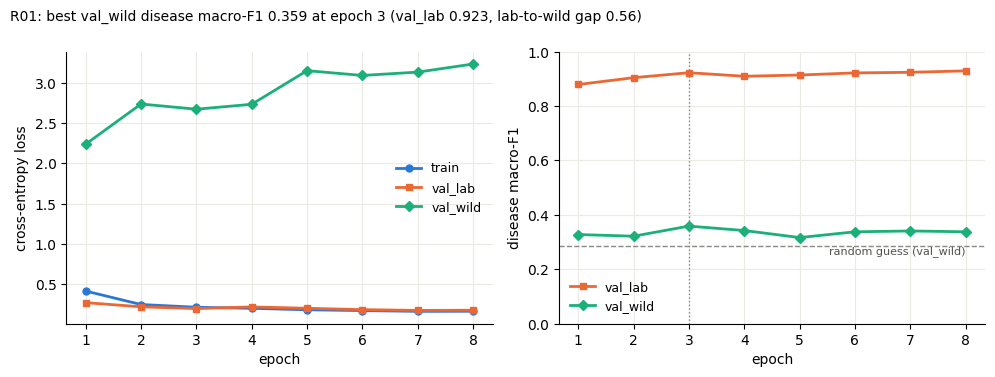

In [11]:
from plots import plot_history
plot_history("R01");